# DeepSeek-V4 from Scratch in NumPy — Compressed Sparse Attention, Manifold-Constrained Residuals, Muon

This notebook works through the architecture of **DeepSeek-V4** (DeepSeek-AI,
technical report [arXiv:2606.19348](https://arxiv.org/abs/2606.19348)) in pure
NumPy, on an eight-token sentence, with every intermediate number printed.

DeepSeek-V4 is a Mixture-of-Experts model built for **one-million-token
context**. Two variants: **V4-Flash** (284B total, 13B activated) and **V4-Pro**
(1.6T total, 49B activated). The headline claim is efficiency — in the 1M-token
setting the KV cache is about **2%** the size of a BF16 GQA-8 baseline, and a
single token's inference costs **27% of the FLOPs** of DeepSeek-V3.2 with **10%
of the KV cache**.

Three ideas do that work, and this notebook takes each one apart:

| § | Mechanism | Equations | The problem it solves |
|---|---|---|---|
| 2 | **mHC** — Manifold-Constrained Hyper-Connections | 1–8 | Widening the residual stream makes deep stacks numerically unstable |
| 3 | **CSA** — Compressed Sparse Attention | 9–19 | KV cache and attention FLOPs at long context |
| 4 | **HCA** — Heavily Compressed Attention | 20–26 | The same, more aggressively, on alternating layers |
| 5 | Normalisation, partial RoPE, sliding window, attention sink | 27 | The details that make the above actually train |
| 6 | DeepSeekMoE, with the V4 changes | — | Sparsity, and what changed from V3 |
| 7 | **Muon** with hybrid Newton–Schulz | 28 | Faster, more stable optimisation than AdamW |

Everything is computed on a deliberately tiny model so the matrices fit on a
screen. The real configuration is quoted alongside each one so you can see which
numbers are toy and which are DeepSeek's.

**No code is shown on this page** — only the explanations, the formulas, and the
numbers that come out.

## 1. The problem, in numbers

Attention cost is the reason this architecture looks the way it does. Before any
mechanism, it is worth seeing the size of the thing being fixed.

A standard **GQA-8** layer with head dimension 128 stores, for every token, 8 key
vectors and 8 value vectors. In BF16 that is

$$\text{bytes per token per layer} = 2 \times n_{\text{kv}} \times d_{\text{head}} \times 2 = 2 \times 8 \times 128 \times 2 = 4096\ \text{bytes}$$

Multiply by a million tokens and by the number of layers and the number stops
being reasonable. That is the wall DeepSeek-V4 is built against.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

banner("THE LONG-CONTEXT KV CACHE PROBLEM")

n_ctx   = 1_000_000
LAYERS  = 43            # DeepSeek-V4-Flash

# --- baseline: BF16 GQA-8, head dim 128 -------------------------------------
n_kv, d_head, bytes_bf16 = 8, 128, 2
per_tok_layer = 2 * n_kv * d_head * bytes_bf16
print(f"  baseline: BF16 GQA-8, head dim {d_head}")
print(f"    per token per layer = 2 x {n_kv} x {d_head} x {bytes_bf16} B"
      f" = {per_tok_layer:,} B")
total = per_tok_layer * n_ctx * LAYERS
print(f"    x {n_ctx:,} tokens x {LAYERS} layers"
      f" = {total/2**30:,.0f} GiB")

print()
print(f"  {total/2**30:,.0f} GiB is the cache for ONE request at 1M context.")
print("  An 80 GiB accelerator holds none of it, let alone a batch of them.")

step("Where DeepSeek-V4 spends its cache instead")
m, m_hca, c = 4, 128, 512

print(f"  CSA compresses every m={m} tokens into one KV entry   ->"
      f" {n_ctx:,} -> {n_ctx//m:,} entries")
print(f"  HCA compresses every m'={m_hca} tokens into one entry ->"
      f" {n_ctx:,} -> {n_ctx//m_hca:,} entries")
print()
print(f"  and the entries are shared across all heads (MQA), not one per head:")
print(f"    CSA: {n_ctx//m:,} x {c} values")
print(f"    HCA: {n_ctx//m_hca:,} x {c} values")
print()
print("  The paper reports the combined effect as ~2% of the BF16 GQA-8")
print("  baseline at 1M context. Section 8 rebuilds that number.")

step("The other half of the problem: attention FLOPs")
topk = 512
print(f"  Even with a short cache, dense attention still scores every entry.")
print(f"  CSA scores {n_ctx//m:,} compressed entries with a cheap indexer, then")
print(f"  runs full attention over only the top-k = {topk} of them.")
print()
print(f"    dense over compressed : {n_ctx//m:,} entries attended")
print(f"    CSA sparse            : {topk:,} entries attended"
      f"   ({topk/(n_ctx//m)*100:.1f}% of them)")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.
  THE LONG-CONTEXT KV CACHE PROBLEM
  baseline: BF16 GQA-8, head dim 128
    per token per layer = 2 x 8 x 128 x 2 B = 4,096 B
    x 1,000,000 tokens x 43 layers = 164 GiB

  164 GiB is the cache for ONE request at 1M context.
  An 80 GiB accelerator holds none of it, let alone a batch of them.

Where DeepSeek-V4 spends its cache instead
  CSA compresses every m=4 tokens into one KV entry   -> 1,000,000 -> 250,000 entries
  HCA compresses every m'=128 tokens into one entry -> 1,000,000 -> 7,812 entries

  and the entries are shared across all heads (MQA), not one per head:
    CSA: 250,000 x 512 values
    HCA: 7,812 x 512 values

  The paper reports the combined effect as ~2% of the BF16 GQA-8
  baseline at 1M context. Section 8 rebuilds that number.

The other half of the problem: attention FLOPs
  Even with a short cache, dense attention still scores every entry.
  CSA scores 250,000 comp

## 2. Manifold-Constrained Hyper-Connections (mHC)

### 2.1 What a hyper-connection is

An ordinary transformer block is

$$x_{l+1} = x_l + \mathcal{F}_l(x_l)$$

one residual stream of width $d$. **Hyper-connections** (Zhu et al., 2025) widen
that stream by a factor $n_{\text{hc}}$, so the state carried between blocks is a
matrix $X_l \in \mathbb{R}^{n_{\text{hc}} \times d}$ rather than a vector. Three
small learned maps connect it to the block:

- $A_l \in \mathbb{R}^{1 \times n_{\text{hc}}}$ — mixes the streams down to the one vector the layer actually sees
- $B_l \in \mathbb{R}^{n_{\text{hc}} \times n_{\text{hc}}}$ — mixes the streams among themselves
- $C_l \in \mathbb{R}^{n_{\text{hc}} \times 1}$ — writes the layer output back out across the streams

$$X_{l+1} = B_l X_l + C_l\,\mathcal{F}_l(A_l X_l) \qquad (1)$$

The layer $\mathcal{F}_l$ still takes and returns a $d$-vector, so **nothing
inside the block changes** — the width $n_{\text{hc}}$ is a new scaling axis that
costs almost nothing, since $n_{\text{hc}} \ll d$. DeepSeek-V4 uses
$n_{\text{hc}} = 4$; this notebook uses 3 so the matrices print small.

Setting $n_{\text{hc}} = 1$, $A = B = C = 1$ recovers the ordinary residual
connection exactly — worth checking, and the notebook does.

In [2]:
banner("HYPER-CONNECTIONS: THE RESIDUAL STREAM BECOMES A MATRIX")

d, n_hc = 8, 3          # paper: d=4096, n_hc=4
tokens  = ["the", "cat", "sat", "on", "the", "mat", "and", "slept"]
T       = len(tokens)

step("Eq 1  X_{l+1} = B_l X_l + C_l F_l(A_l X_l)")
print(f"  n_hc = {n_hc}  ->  the state between blocks is ({n_hc} x {d}),"
      f" not ({d},)")
print()
print("  shapes:")
print(f"    X_l      ({n_hc} x {d})     the widened residual state")
print(f"    A_l      (1 x {n_hc})     stream mixer, down to what the layer sees")
print(f"    A_l X_l  (1 x {d})     <- the layer input: still just d-dimensional")
print(f"    B_l      ({n_hc} x {n_hc})     stream-to-stream mixing")
print(f"    C_l      ({n_hc} x 1)     writes the layer output back to the streams")

step("Sanity: n_hc = 1 with A = B = C = 1 must be the ordinary residual")
x  = np.random.randn(1, d)
Fx = np.random.randn(1, d)          # pretend layer output
A1 = np.ones((1, 1)); B1 = np.ones((1, 1)); C1 = np.ones((1, 1))
hc  = B1 @ x + C1 @ Fx
res = x + Fx
print(f"  hyper-connection : {np.round(hc[0][:5], 4)} ...")
print(f"  x + F(x)         : {np.round(res[0][:5], 4)} ...")
print(f"  max|diff| = {np.abs(hc-res).max():.2e}   MATCH: "
      f"{np.allclose(hc, res)}")
print()
print("  So hyper-connections strictly generalise the residual connection.")

  HYPER-CONNECTIONS: THE RESIDUAL STREAM BECOMES A MATRIX

Eq 1  X_{l+1} = B_l X_l + C_l F_l(A_l X_l)
  n_hc = 3  ->  the state between blocks is (3 x 8), not (8,)

  shapes:
    X_l      (3 x 8)     the widened residual state
    A_l      (1 x 3)     stream mixer, down to what the layer sees
    A_l X_l  (1 x 8)     <- the layer input: still just d-dimensional
    B_l      (3 x 3)     stream-to-stream mixing
    C_l      (3 x 1)     writes the layer output back to the streams

Sanity: n_hc = 1 with A = B = C = 1 must be the ordinary residual
  hyper-connection : [0.0272 0.4043 0.1843 1.0573 0.0078] ...
  x + F(x)         : [0.0272 0.4043 0.1843 1.0573 0.0078] ...
  max|diff| = 0.00e+00   MATCH: True

  So hyper-connections strictly generalise the residual connection.


### 2.2 Why $B_l$ must be constrained

Equation (1) applies $B_l$ to the residual state at **every layer**. Across $L$
layers the stream has been multiplied by $B_L B_{L-1} \cdots B_1$. If those
matrices have spectral norm above 1, the product grows geometrically — with 43
layers, a spectral norm of 1.1 is a factor of $1.1^{43} \approx 60$, and 1.3 is a
factor of over 40,000. That is the numerical instability the paper reports when
scaling plain hyper-connections.

mHC's fix is to constrain $B_l$ to the **Birkhoff polytope** — the set of doubly
stochastic matrices:

$$B_l \in \mathcal{M} := \{M \in \mathbb{R}^{n\times n} \mid M\mathbf{1}_n = \mathbf{1}_n,\ \mathbf{1}_n^T M = \mathbf{1}_n^T,\ M \geqslant 0\} \qquad (2)$$

Non-negative, every row sums to 1, every column sums to 1. Two properties follow,
and both matter:

1. $\|B_l\|_2 \leqslant 1$ — the map is **non-expansive**, so signals cannot blow up going forward or backward.
2. $\mathcal{M}$ is **closed under multiplication** — a product of doubly stochastic matrices is doubly stochastic, so the guarantee survives stacking to any depth.

The demonstration below is the whole argument for mHC in one table.

In [3]:
banner("WHY THE RESIDUAL MIXER MUST BE NON-EXPANSIVE")

L = 43                                   # DeepSeek-V4-Flash depth
step("A spectral norm slightly above 1, compounded over 43 layers")
print(f"  {'||B||_2':>9}  {'||B||^43':>14}   effect on the residual stream")
print("  " + "-" * 62)
for s in [0.9, 1.0, 1.05, 1.1, 1.3]:
    g = s ** L
    note = ("shrinks to nothing" if g < 0.05 else
            "stable" if g <= 1.0 else
            "grows" if g < 100 else "explodes")
    print(f"  {s:>9.2f}  {g:>14.4g}   {note}")
print("  " + "-" * 62)
print("  Doubly stochastic guarantees the 1.00 row, for every layer, forever.")

step("Property 1: doubly stochastic => spectral norm exactly bounded by 1")
def rand_doubly_stochastic(n, iters=200, seed=0):
    rng = np.random.RandomState(seed)
    M = np.exp(rng.randn(n, n))
    for _ in range(iters):
        M = M / M.sum(0, keepdims=True)
        M = M / M.sum(1, keepdims=True)
    return M

for seed in range(4):
    B  = rand_doubly_stochastic(n_hc, seed=seed)
    sv = np.linalg.svd(B, compute_uv=False)
    print(f"    seed {seed}:  ||B||_2 = {sv[0]:.6f}   row sums"
          f" {np.round(B.sum(1), 6)}   col sums {np.round(B.sum(0), 6)}")
print()
print("  The top singular value is 1.000000 every time - exactly, not")
print("  approximately, and the reason is a theorem rather than an accident:")
print("    Birkhoff-von Neumann says every doubly stochastic matrix is a")
print("    convex combination of permutation matrices. Each permutation has")
print("    spectral norm 1, and the spectral norm is convex, so ||B||_2 <= 1.")
print("    And B1 = 1 forces ||B||_2 >= 1. Hence exactly 1.")

step("Property 2: closed under multiplication (so depth is safe)")
P = np.eye(n_hc)
print(f"  {'layers':>7}  {'||prod||_2':>11}  {'max row sum':>12}  {'max col sum':>12}")
print("  " + "-" * 48)
for l in range(1, L + 1):
    P = rand_doubly_stochastic(n_hc, seed=l) @ P
    if l in (1, 2, 5, 10, 20, 43):
        print(f"  {l:>7}  {np.linalg.svd(P, compute_uv=False)[0]:>11.6f}"
              f"  {P.sum(1).max():>12.6f}  {P.sum(0).max():>12.6f}")
print("  " + "-" * 48)
print("  43 layers deep and the product is still doubly stochastic,")
print("  still non-expansive. Compare the 1.1 row of the first table.")

step("The contrast: unconstrained B, the same 43 layers")
P = np.eye(n_hc)
rng = np.random.RandomState(0)
for l in range(1, L + 1):
    P = (rng.randn(n_hc, n_hc) / np.sqrt(n_hc)) @ P
    if l in (1, 5, 10, 20, 43):
        print(f"    after {l:>2} layers: ||prod||_2 = "
              f"{np.linalg.svd(P, compute_uv=False)[0]:.4e}")
print()
print("  This is why plain hyper-connections were reported as unstable.")

  WHY THE RESIDUAL MIXER MUST BE NON-EXPANSIVE

A spectral norm slightly above 1, compounded over 43 layers
    ||B||_2        ||B||^43   effect on the residual stream
  --------------------------------------------------------------
       0.90         0.01078   shrinks to nothing
       1.00               1   stable
       1.05            8.15   grows
       1.10           60.24   grows
       1.30       7.935e+04   explodes
  --------------------------------------------------------------
  Doubly stochastic guarantees the 1.00 row, for every layer, forever.

Property 1: doubly stochastic => spectral norm exactly bounded by 1
    seed 0:  ||B||_2 = 1.000000   row sums [1. 1. 1.]   col sums [1. 1. 1.]
    seed 1:  ||B||_2 = 1.000000   row sums [1. 1. 1.]   col sums [1. 1. 1.]
    seed 2:  ||B||_2 = 1.000000   row sums [1. 1. 1.]   col sums [1. 1. 1.]
    seed 3:  ||B||_2 = 1.000000   row sums [1. 1. 1.]   col sums [1. 1. 1.]

  The top singular value is 1.000000 every time - exactly, n

### 2.3 Where $A_l$, $B_l$, $C_l$ come from

They are not free parameters. Each is **generated from the input itself** — a
dynamic, input-dependent part plus a static learned bias. First the widened state
is flattened and normalised:

$$\hat{X}_l = \operatorname{RMSNorm}(\operatorname{vec}(X_l)) \in \mathbb{R}^{1 \times n_{\text{hc}}d}$$

then

$$\tilde{A}_l = \alpha_l^{\mathrm{pre}} \cdot (\hat{X}_l W_l^{\mathrm{pre}}) + S_l^{\mathrm{pre}} \qquad (3)$$
$$\tilde{B}_l = \alpha_l^{\mathrm{res}} \cdot \operatorname{Mat}(\hat{X}_l W_l^{\mathrm{res}}) + S_l^{\mathrm{res}} \qquad (4)$$
$$\tilde{C}_l = \alpha_l^{\mathrm{post}} \cdot (\hat{X}_l W_l^{\mathrm{post}})^T + S_l^{\mathrm{post}} \qquad (5)$$

$\operatorname{Mat}(\cdot)$ reshapes a $1 \times n_{\text{hc}}^2$ vector into an
$n_{\text{hc}} \times n_{\text{hc}}$ matrix. The gates
$\alpha^{\mathrm{pre}}, \alpha^{\mathrm{res}}, \alpha^{\mathrm{post}}$ are
learnable scalars **initialised to small values** — so at the start of training
the maps are essentially the static biases, and the dynamic part fades in.

Then the constraints. $A_l$ and $C_l$ are squashed to be non-negative and bounded,
which prevents the streams from cancelling each other:

$$A_l = \sigma(\tilde{A}_l) \qquad (6) \qquad\qquad C_l = 2\,\sigma(\tilde{C}_l) \qquad (7)$$

Note the factor 2 on $C_l$: $\sigma$ alone caps the output-write at 1, and the
paper allows the layer output to be written with weight up to 2.

In [4]:
banner("mHC PARAMETERISATION (EQ 3-7), BY HAND")

rng = np.random.RandomState(7)
X_l = rng.randn(n_hc, d) * 0.6          # the widened residual state

step("Flatten and RMSNorm the state  (the input to all three generators)")
vec = X_l.reshape(1, -1)
rms = np.sqrt((vec ** 2).mean() + 1e-6)
Xhat = vec / rms
print(f"  vec(X_l) shape {vec.shape}   (n_hc x d = {n_hc} x {d} = {n_hc*d})")
print(f"  mean square = {(vec**2).mean():.6f}   rms = {rms:.6f}")
print(f"  Xhat[:8] = {np.round(Xhat[0][:8], 4)}")

step("Eq 3-5: dynamic component + static bias")
W_pre  = rng.randn(n_hc * d, n_hc)      * 0.1
W_res  = rng.randn(n_hc * d, n_hc ** 2) * 0.1
W_post = rng.randn(n_hc * d, n_hc)      * 0.1
S_pre  = rng.randn(1, n_hc)     * 0.3
S_res  = rng.randn(n_hc, n_hc)  * 0.3
S_post = rng.randn(n_hc, 1)     * 0.3
a_pre, a_res, a_post = 0.05, 0.05, 0.05     # "initialised to small values"

A_t = a_pre  * (Xhat @ W_pre) + S_pre
B_t = a_res  * (Xhat @ W_res).reshape(n_hc, n_hc) + S_res
C_t = a_post * (Xhat @ W_post).T + S_post

print(f"  alpha_pre = alpha_res = alpha_post = {a_pre}  (small at init)")
print()
print(f"  A~ (1 x {n_hc})  = {np.round(A_t[0], 4)}")
print(f"  B~ ({n_hc} x {n_hc}) =")
for r in B_t: print(f"        {np.round(r, 4)}")
print(f"  C~ ({n_hc} x 1)  = {np.round(C_t[:, 0], 4)}")

step("Eq 6-7: squash A and C so the streams cannot cancel")
sig = lambda z: 1.0 / (1.0 + np.exp(-z))
A_l = sig(A_t)
C_l = 2 * sig(C_t)
print(f"  A = sigma(A~)     = {np.round(A_l[0], 4)}     all in (0, 1)"
      f"   -> {bool(((A_l > 0) & (A_l < 1)).all())}")
print(f"  C = 2 sigma(C~)   = {np.round(C_l[:, 0], 4)}     all in (0, 2)"
      f"   -> {bool(((C_l > 0) & (C_l < 2)).all())}")
print()
print("  Non-negative means every stream contributes with the same sign.")
print("  Nothing can be subtracted away, which is the 'signal cancellation'")
print("  the paper is guarding against.")

  mHC PARAMETERISATION (EQ 3-7), BY HAND

Flatten and RMSNorm the state  (the input to all three generators)
  vec(X_l) shape (1, 24)   (n_hc x d = 3 x 8 = 24)
  mean square = 0.314985   rms = 0.561236
  Xhat[:8] = [ 1.8073 -0.4981  0.0351  0.4357 -0.8434  0.0022 -0.001  -1.8759]

Eq 3-5: dynamic component + static bias
  alpha_pre = alpha_res = alpha_post = 0.05  (small at init)

  A~ (1 x 3)  = [-0.8969 -0.5156 -0.0245]
  B~ (3 x 3) =
        [-0.0405  0.1218 -0.0654]
        [ 0.0326  0.2282 -0.2934]
        [-0.1119 -0.5032  0.283 ]
  C~ (3 x 1)  = [0.0637 0.1459 0.4918]

Eq 6-7: squash A and C so the streams cannot cancel
  A = sigma(A~)     = [0.2897 0.3739 0.4939]     all in (0, 1)   -> True
  C = 2 sigma(C~)   = [1.0318 1.0728 1.2411]     all in (0, 2)   -> True

  Non-negative means every stream contributes with the same sign.
  Nothing can be subtracted away, which is the 'signal cancellation'
  the paper is guarding against.


### 2.4 Projecting $B_l$ onto the Birkhoff polytope: Sinkhorn–Knopp

$\tilde{B}_l$ from equation (4) is an arbitrary matrix. It has to become doubly
stochastic. The projection is **Sinkhorn–Knopp**: exponentiate to force
positivity, then alternately normalise columns and rows until both sum to 1.

$$M^{(0)} = \exp(\tilde{B}_l), \qquad M^{(t)} = \mathcal{T}_r\big(\mathcal{T}_c(M^{(t-1)})\big) \qquad (8)$$

with $B_l = M^{(t_{\max})}$ and DeepSeek using $t_{\max} = 20$.

Each half-step is trivial — divide every column by its sum, then every row by its
sum. The subtlety is that fixing the rows breaks the columns again, slightly. The
iteration works because it breaks them *less* each time; it converges
geometrically. Watch the two error columns below fall together.

In [5]:
banner("SINKHORN-KNOPP: PROJECTING B~ ONTO THE DOUBLY STOCHASTIC MANIFOLD")

step("Eq 8, iterated by hand")
M = np.exp(B_t)
print("  M(0) = exp(B~)  -- positive, but sums are arbitrary:")
for r in M: print(f"        {np.round(r, 4)}")
print(f"    row sums {np.round(M.sum(1), 4)}   col sums {np.round(M.sum(0), 4)}")

print()
print(f"  {'iter':>5}  {'max|rowsum-1|':>14}  {'max|colsum-1|':>14}  {'||M||_2':>9}")
print("  " + "-" * 50)
for t in range(1, 21):
    M = M / M.sum(0, keepdims=True)      # T_c : column normalisation
    M = M / M.sum(1, keepdims=True)      # T_r : row normalisation
    if t <= 5 or t in (10, 20):
        er = np.abs(M.sum(1) - 1).max()
        ec = np.abs(M.sum(0) - 1).max()
        print(f"  {t:>5}  {er:>14.2e}  {ec:>14.2e}"
              f"  {np.linalg.svd(M, compute_uv=False)[0]:>9.6f}")
print("  " + "-" * 50)

B_l = M
print()
print("  B = M(20):")
for r in B_l: print(f"        {np.round(r, 6)}")
print(f"    row sums {np.round(B_l.sum(1), 8)}")
print(f"    col sums {np.round(B_l.sum(0), 8)}")
print(f"    all entries >= 0 : {bool((B_l >= 0).all())}")
sv = np.linalg.svd(B_l, compute_uv=False)
print(f"    singular values  : {np.round(sv, 6)}")
print(f"    ||B||_2 = {sv[0]:.8f} <= 1 : {sv[0] <= 1 + 1e-9}")

step("Note which normalisation goes last, and why the row error is smaller")
print("  Eq 8 is T_r(T_c(.)) - columns first, then rows. So after the final")
print("  half-step the ROWS are exactly 1 and the columns are 1 only to the")
print("  accuracy reached so far. That asymmetry is visible in the table above:")
print(f"    |rowsum-1| = {np.abs(B_l.sum(1)-1).max():.2e}"
      f"   <- exact, it was normalised last")
print(f"    |colsum-1| = {np.abs(B_l.sum(0)-1).max():.2e}"
      f"   <- the residual error")
print()
print("  At t_max=20 the column error is far below bf16 resolution (~4e-3),")
print("  so the matrix is doubly stochastic as far as the model can tell.")

  SINKHORN-KNOPP: PROJECTING B~ ONTO THE DOUBLY STOCHASTIC MANIFOLD

Eq 8, iterated by hand
  M(0) = exp(B~)  -- positive, but sums are arbitrary:
        [0.9603 1.1295 0.9367]
        [1.0331 1.2563 0.7458]
        [0.8941 0.6046 1.3272]
    row sums [3.0266 3.0352 2.8259]   col sums [2.8875 2.9904 3.0097]

   iter   max|rowsum-1|   max|colsum-1|    ||M||_2
  --------------------------------------------------
      1        1.11e-16        9.09e-03   1.000027
      2        2.22e-16        4.36e-04   1.000000
      3        1.11e-16        2.09e-05   1.000000
      4        0.00e+00        9.99e-07   1.000000
      5        0.00e+00        4.78e-08   1.000000
     10        1.11e-16        1.20e-14   1.000000
     20        0.00e+00        0.00e+00   1.000000
  --------------------------------------------------

  B = M(20):
        [0.3256 0.3728 0.3016]
        [0.3485 0.4126 0.2389]
        [0.3259 0.2146 0.4595]
    row sums [1. 1. 1.]
    col sums [1. 1. 1.]
    all entries >= 0

### 2.5 One full mHC block

All the pieces, applied through equation (1) once. The thing to watch in the
output is the last table: the mHC block leaves the norm of the residual state
essentially unchanged, while the unconstrained version does not.

In [6]:
banner("ONE mHC BLOCK, END TO END (EQ 1)")

def fake_layer(u):
    """Stands in for the attention or MoE layer. Shape d -> d."""
    return np.tanh(u @ Wf) * 0.8

Wf = np.random.RandomState(3).randn(d, d) * 0.4

step("Eq 1: X_{l+1} = B X_l + C F(A X_l)")
u = A_l @ X_l                       # (1 x n_hc) @ (n_hc x d) -> (1 x d)
print(f"  A X_l  ({A_l.shape} @ {X_l.shape} -> {u.shape})"
      f"  = the d-vector the layer sees")
print(f"    {np.round(u[0], 4)}")

Fu = fake_layer(u)
print(f"\n  F(A X_l) = {np.round(Fu[0], 4)}")

mix   = B_l @ X_l
write = C_l @ Fu
X_next = mix + write
print(f"\n  B X_l      ({mix.shape})   stream mixing")
print(f"  C F(A X_l) ({write.shape})   output written back, weighted per stream")
print(f"    C = {np.round(C_l[:,0], 4)}  -> stream {int(np.argmax(C_l))}"
      f" receives the most")

step("Norm bookkeeping: what mHC buys")
print(f"  {'':22} {'||X||_F':>10}  {'ratio':>8}")
print("  " + "-" * 44)
n0 = np.linalg.norm(X_l)
print(f"  {'before the block':22} {n0:>10.4f}  {1.0:>8.4f}")
print(f"  {'after B X (mixing)':22} {np.linalg.norm(mix):>10.4f}"
      f"  {np.linalg.norm(mix)/n0:>8.4f}   <= 1, guaranteed")
print(f"  {'after full block':22} {np.linalg.norm(X_next):>10.4f}"
      f"  {np.linalg.norm(X_next)/n0:>8.4f}   grows only by what F added")
print("  " + "-" * 44)
print("  The mixing step can never amplify. Any growth in the residual stream")
print("  comes from the layer's own output, which is what you want -- it is")
print("  the uncontrolled compounding of B that mHC removes.")

step("The same block with an UNCONSTRAINED B, for contrast")
X_a, X_b = X_l.copy(), X_l.copy()
Bu = np.random.RandomState(11).randn(n_hc, n_hc) / np.sqrt(n_hc)
print(f"  ||B_mHC||_2 = {np.linalg.svd(B_l, compute_uv=False)[0]:.4f}"
      f"      ||B_unc||_2 = {np.linalg.svd(Bu, compute_uv=False)[0]:.4f}")
print()
print(f"  {'block':>6}  {'||X|| mHC':>12}  {'||X|| unconstrained':>21}")
print("  " + "-" * 44)
for blk in range(1, 21):
    X_a = B_l @ X_a + C_l @ fake_layer(A_l @ X_a)
    X_b = Bu  @ X_b + C_l @ fake_layer(A_l @ X_b)
    if blk in (1, 5, 10, 15, 20):
        print(f"  {blk:>6}  {np.linalg.norm(X_a):>12.4f}"
              f"  {np.linalg.norm(X_b):>21.4e}")
print("  " + "-" * 44)
print("  Same layer, same C, same input. Only the constraint on B differs.")

  ONE mHC BLOCK, END TO END (EQ 1)

Eq 1: X_{l+1} = B X_l + C F(A X_l)
  A X_l  ((1, 3) @ (3, 8) -> (1, 8))  = the d-vector the layer sees
    [ 0.6865  0.0904 -0.0533 -0.42    0.4654 -0.0125 -0.1693 -0.0297]

  F(A X_l) = [ 0.425   0.1392 -0.2735 -0.5753 -0.1163 -0.2123 -0.05   -0.3658]

  B X_l      ((3, 8))   stream mixing
  C F(A X_l) ((3, 8))   output written back, weighted per stream
    C = [1.0318 1.0728 1.2411]  -> stream 2 receives the most

Norm bookkeeping: what mHC buys
                            ||X||_F     ratio
  --------------------------------------------
  before the block           2.7495    1.0000
  after B X (mixing)         1.4482    0.5267   <= 1, guaranteed
  after full block           2.9194    1.0618   grows only by what F added
  --------------------------------------------
  The mixing step can never amplify. Any growth in the residual stream
  comes from the layer's own output, which is what you want -- it is
  the uncontrolled compounding of B that mHC r

## 3. Compressed Sparse Attention (CSA)

CSA attacks the cache and the FLOPs in two separate stages:

1. **Compress** — every $m$ tokens collapse into one KV entry, so the sequence the attention sees is $n/m$ long. DeepSeek uses $m=4$.
2. **Select** — a cheap "lightning indexer" scores those compressed entries and full attention runs over only the top $k$. DeepSeek uses $k=512$.

Stage 1 shrinks the cache. Stage 2 shrinks the compute. They are independent, and
the paper applies both.

### 3.1 Building the compressed KV entries

Two separate KV projections and two compression-weight projections are computed
from the hidden states $H \in \mathbb{R}^{n \times d}$:

$$C^a = H W^{aKV}, \quad C^b = H W^{bKV} \qquad (9)$$
$$Z^a = H W^{aZ}, \quad Z^b = H W^{bZ} \qquad (10)$$

Then compressed entry $i$ pools $2m$ source tokens — $m$ from the $a$ stream at
positions $[mi,\ m(i{+}1))$ and $m$ from the $b$ stream at the *previous* block
$[m(i{-}1),\ mi)$ — with a softmax over all $2m$ of them, plus learnable
positional biases $B^a, B^b \in \mathbb{R}^{m \times c}$:

$$[S^a; S^b] = \operatorname{Softmax}_{\text{row}}\big([Z^a + B^a;\ Z^b + B^b]\big) \qquad (11)$$
$$C^{\text{Comp}}_i = \sum_{j=mi}^{m(i+1)-1} S^a_j \odot C^a_j \;+\; \sum_{j=m(i-1)}^{mi-1} S^b_j \odot C^b_j \qquad (12)$$

Two things are easy to misread here:

- The softmax is **per channel**, not per token. Each of the $c$ dimensions gets its own distribution over the $2m$ contributing tokens. That is why $B^a$ is $m \times c$ and why $\odot$ appears rather than a scalar weight.
- Each entry draws on $2m$ tokens, but consecutive entries **overlap** — the $b$-half of entry $i$ covers the same positions as the $a$-half of entry $i-1$. So the compression ratio is $1/m$, not $1/2m$. The overlap exists so information near a block boundary is not cut in half.

At $i=0$ there is no previous block, so $Z^b$ is padded with $-\infty$ (weight
zero after softmax) and $C^b$ with zeros.

In [7]:
banner("CSA STAGE 1: COMPRESSING THE KV CACHE (EQ 9-12)")

m_csa, c_dim = 2, 4          # paper: m=4, c=512
H = np.random.RandomState(1).randn(T, d) * 0.7
n_blocks = T // m_csa

step("Eq 9-10: two KV streams and two weight streams")
rng = np.random.RandomState(21)
W_aKV, W_bKV = rng.randn(d, c_dim)*0.3, rng.randn(d, c_dim)*0.3
W_aZ,  W_bZ  = rng.randn(d, c_dim)*0.3, rng.randn(d, c_dim)*0.3
Ca, Cb = H @ W_aKV, H @ W_bKV
Za, Zb = H @ W_aZ,  H @ W_bZ
print(f"  H ({T} x {d}) -> Ca, Cb, Za, Zb each ({T} x {c_dim})")
print(f"  m = {m_csa}, so {T} tokens -> {n_blocks} compressed entries"
      f"  (ratio 1/{m_csa})")
print()
print(f"  {'token':>9}  Ca (the 'a' KV stream)")
for t in range(T):
    print(f"  {t}:{tokens[t]:<7}  {np.round(Ca[t], 4)}")

step("Eq 11-12: pooling 2m tokens into entry i, one channel at a time")
Ba = rng.randn(m_csa, c_dim) * 0.2       # learnable positional biases
Bb = rng.randn(m_csa, c_dim) * 0.2

def csa_compress(Ca, Cb, Za, Zb, m):
    nb = Ca.shape[0] // m
    out, weights = np.zeros((nb, Ca.shape[1])), []
    for i in range(nb):
        za = Za[m*i:m*(i+1)] + Ba
        if i == 0:
            zb = np.full((m, Ca.shape[1]), -np.inf)
            cb = np.zeros((m, Ca.shape[1]))
        else:
            zb = Zb[m*(i-1):m*i] + Bb
            cb = Cb[m*(i-1):m*i]
        z = np.concatenate([za, zb], axis=0)              # (2m x c)
        e = np.exp(z - z.max(axis=0, keepdims=True))      # softmax down columns
        s = e / e.sum(axis=0, keepdims=True)
        out[i] = (s[:m] * Ca[m*i:m*(i+1)]).sum(0) + (s[m:] * cb).sum(0)
        weights.append(s)
    return out, weights

C_comp, Wts = csa_compress(Ca, Cb, Za, Zb, m_csa)

i = 1
print(f"  Entry {i} in full. It pools 2m = {2*m_csa} tokens:")
print(f"    from Ca: positions {list(range(m_csa*i, m_csa*(i+1)))}"
      f"  ({', '.join(tokens[p] for p in range(m_csa*i, m_csa*(i+1)))})")
print(f"    from Cb: positions {list(range(m_csa*(i-1), m_csa*i))}"
      f"  ({', '.join(tokens[p] for p in range(m_csa*(i-1), m_csa*i))})")
print()
s = Wts[i]
print(f"  softmax weights S, shape {s.shape} = (2m x c) -- one column per channel:")
lbl = ([f"a:{tokens[p]}" for p in range(m_csa*i, m_csa*(i+1))] +
       [f"b:{tokens[p]}" for p in range(m_csa*(i-1), m_csa*i)])
print(f"    {'source':>10} " + "".join(f"{f'ch{j}':>9}" for j in range(c_dim)))
for r in range(2*m_csa):
    print(f"    {lbl[r]:>10} " + "".join(f"{s[r,j]:>9.4f}" for j in range(c_dim)))
print(f"    {'sum':>10} " + "".join(f"{s[:,j].sum():>9.4f}" for j in range(c_dim)))
print("    ^ each COLUMN sums to 1: the softmax is per channel, not per token.")

print()
print(f"  Channel 0 of entry {i}, by hand:")
terms = []
for r in range(m_csa):
    terms.append(f"{s[r,0]:.4f}x{Ca[m_csa*i+r,0]:+.4f}")
for r in range(m_csa):
    terms.append(f"{s[m_csa+r,0]:.4f}x{Cb[m_csa*(i-1)+r,0]:+.4f}")
print(f"    " + " + ".join(terms))
manual = ((s[:m_csa,0]*Ca[m_csa*i:m_csa*(i+1),0]).sum() +
          (s[m_csa:,0]*Cb[m_csa*(i-1):m_csa*i,0]).sum())
print(f"    = {manual:+.6f}   |  from array: {C_comp[i,0]:+.6f}"
      f"   |  MATCH: {np.allclose(manual, C_comp[i,0])}")

step("Entry 0 has no previous block")
print(f"  Z^b padded with -inf -> softmax weight exactly 0:")
print(f"    b-stream weights for entry 0: {np.round(Wts[0][m_csa:], 8).tolist()}")
print(f"    so entry 0 is built from its own {m_csa} tokens only.")

step("All compressed entries")
print(f"  {'entry':>6}  {'pools tokens':<28}  values")
for i in range(n_blocks):
    src = ([tokens[p] for p in range(m_csa*(i-1), m_csa*i)] if i else []) + \
          [tokens[p] for p in range(m_csa*i, m_csa*(i+1))]
    print(f"  {i:>6}  {','.join(src):<28}  {np.round(C_comp[i], 4)}")
print()
print(f"  {T} tokens -> {n_blocks} entries stored. The cache is now 1/{m_csa} the size.")

  CSA STAGE 1: COMPRESSING THE KV CACHE (EQ 9-12)

Eq 9-10: two KV streams and two weight streams
  H (8 x 8) -> Ca, Cb, Za, Zb each (8 x 4)
  m = 2, so 8 tokens -> 4 compressed entries  (ratio 1/2)

      token  Ca (the 'a' KV stream)
  0:the      [-0.5257  0.837   0.2688  0.6445]
  1:cat      [-0.5628  0.333  -0.4925  0.6301]
  2:sat      [-0.5496  0.0552  0.5517 -0.16  ]
  3:on       [-0.3368  0.144  -0.0969 -0.598 ]
  4:the      [-0.9654  0.4037  0.7164  0.3985]
  5:mat      [0.1386 0.5323 1.1035 0.5396]
  6:and      [ 0.0938 -0.0878  0.4143  0.2956]
  7:slept    [ 0.0686 -0.8028  0.288  -0.7824]

Eq 11-12: pooling 2m tokens into entry i, one channel at a time
  Entry 1 in full. It pools 2m = 4 tokens:
    from Ca: positions [2, 3]  (sat, on)
    from Cb: positions [0, 1]  (the, cat)

  softmax weights S, shape (4, 4) = (2m x c) -- one column per channel:
        source       ch0      ch1      ch2      ch3
         a:sat    0.2444   0.1834   0.5107   0.1603
          a:on    0.1150

### 3.2 The lightning indexer

Now the second stage. Scoring all $n/m$ compressed entries with full attention
would still be expensive at a million tokens, so DeepSeek uses a deliberately
cheap scorer — the **lightning indexer** from DeepSeek Sparse Attention — whose
only job is to rank entries so the top $k$ can be picked.

Queries come from a **low-rank** path, and the latent $\mathbf{c}^Q_t$ is shared
with the real attention queries later (equation 18), so it costs nothing extra:

$$\mathbf{c}^Q_t = \mathbf{h}_t W^{DQ} \qquad (13) \qquad\qquad \mathbf{q}^I_t = \mathbf{c}^Q_t W^{IUQ} \qquad (14)$$

Per-head weights, then the score:

$$\mathbf{w}^I_t = \mathbf{h}_t W^w \qquad (15)$$
$$I_{t,s} = \sum_{h=1}^{n^I_h} w^I_{t,h} \cdot \operatorname{ReLU}\big(\mathbf{q}^I_{t,h} \cdot K^{\text{IComp}}_s\big) \qquad (16)$$

$$\mathcal{C}^{\text{SprsComp}}_t = \big\{ C^{\text{Comp}}_s \ \big|\ I_{t,s} \in \operatorname{Top-}k(I_{t,:}) \big\} \qquad (17)$$

Two details worth pausing on:

- The **ReLU** makes this not an attention score. There is no softmax and no normalisation — negative head-agreements are clipped to zero and the surviving ones are summed with learned per-head weights $w^I_{t,h}$. It is a *ranking* function, cheap by design, and it is trained to imitate which entries the real attention would have wanted.
- Causality is enforced by construction: entry $s$ is only a candidate when $s < \lfloor t/m \rfloor$, so a query never sees a compressed block containing itself or anything after it.

In DeepSeek-V4 the indexer runs in **FP4** — it is the cheapest part of the layer
on purpose.

In [8]:
banner("CSA STAGE 2: THE LIGHTNING INDEXER (EQ 13-17)")

d_c, n_hI, cI, n_h = 6, 3, 4, 2      # paper: d_c=1024, n_hI=64, cI=128, n_h=64
top_k = 2                            # paper: 512

rng = np.random.RandomState(33)
W_DQ  = rng.randn(d, d_c)        * 0.4
W_IUQ = rng.randn(d_c, cI*n_hI)  * 0.4
W_w   = rng.randn(d, n_hI)       * 0.4
W_aKI, W_bKI = rng.randn(d, cI)*0.3, rng.randn(d, cI)*0.3
W_aZI, W_bZI = rng.randn(d, cI)*0.3, rng.randn(d, cI)*0.3

step("Indexer keys: the SAME compression, applied to indexer-key projections")
BaI, BbI = rng.randn(m_csa, cI)*0.2, rng.randn(m_csa, cI)*0.2
_Ba, _Bb = Ba, Bb
Ba, Bb = BaI, BbI
K_IComp, _ = csa_compress(H @ W_aKI, H @ W_bKI, H @ W_aZI, H @ W_bZI, m_csa)
Ba, Bb = _Ba, _Bb
print(f"  K_IComp ({n_blocks} x {cI})  -- indexer head dim c^I = {cI}")

step("Eq 13-14: low-rank indexer queries")
t_q = 7
h_t = H[t_q]
c_Q = h_t @ W_DQ
q_I = (c_Q @ W_IUQ).reshape(n_hI, cI)
print(f"  query token t = {t_q} ('{tokens[t_q]}')")
print(f"    h_t ({d},) @ W_DQ ({d} x {d_c}) -> c_Q ({d_c},) = {np.round(c_Q, 4)}")
print(f"    c_Q @ W_IUQ -> {n_hI} indexer heads of dim {cI}")
print(f"    NOTE: this same c_Q is reused for the real attention queries (Eq 18)")

step("Eq 15: per-head weights")
w_I = h_t @ W_w
print(f"  w_I = {np.round(w_I, 4)}   (can be negative: a head can vote against)")

step("Eq 16: the index score, ReLU then weighted sum -- no softmax")
avail = t_q // m_csa
print(f"  causal limit: s < floor(t/m) = floor({t_q}/{m_csa}) = {avail}")
print(f"  so entries {list(range(avail))} are candidates"
      f" (entry {avail} contains token {t_q} itself)")
print()
print(f"  {'entry':>6}  " + "".join(f"{f'q.k h{h}':>11}" for h in range(n_hI))
      + "  " + "".join(f"{f'ReLU h{h}':>11}" for h in range(n_hI)) + f"{'I(t,s)':>11}")
print("  " + "-" * (6 + 22*n_hI + 13))
I_scores = np.full(n_blocks, -np.inf)
for s_ in range(avail):
    dots = q_I @ K_IComp[s_]
    rel  = np.maximum(dots, 0.0)
    I_scores[s_] = float(w_I @ rel)
    print(f"  {s_:>6}  " + "".join(f"{v:>11.4f}" for v in dots)
          + "  " + "".join(f"{v:>11.4f}" for v in rel)
          + f"{I_scores[s_]:>11.4f}")
print("  " + "-" * (6 + 22*n_hI + 13))

manual = sum(w_I[h] * max(float(q_I[h] @ K_IComp[0]), 0.0) for h in range(n_hI))
print(f"\n  hand check, entry 0: sum_h w_h * ReLU(q_h . k) = {manual:+.6f}")
print(f"    from array: {I_scores[0]:+.6f}   MATCH: "
      f"{np.allclose(manual, I_scores[0])}")

step("Eq 17: keep the top-k")
order = np.argsort(-I_scores)
sel   = np.sort(order[:top_k])
print(f"  ranked: {[int(s_) for s_ in order[:avail]]}"
      f"   -> top-{top_k} = {sel.tolist()}")
print(f"  dropped: {[int(s_) for s_ in order[top_k:avail]]}")
print()
brute = np.sort(np.argsort(-I_scores)[:top_k])
print(f"  top-k vs brute-force sort: MATCH: {np.array_equal(sel, brute)}")
print()
print(f"  At the real scale this is the whole point: {250000:,} compressed")
print(f"  entries scored cheaply, {512:,} kept for full attention.")

  CSA STAGE 2: THE LIGHTNING INDEXER (EQ 13-17)

Indexer keys: the SAME compression, applied to indexer-key projections
  K_IComp (4 x 4)  -- indexer head dim c^I = 4

Eq 13-14: low-rank indexer queries
  query token t = 7 ('slept')
    h_t (8,) @ W_DQ (8 x 6) -> c_Q (6,) = [-0.821  -0.0724  0.7133 -0.1367 -1.0535  0.6349]
    c_Q @ W_IUQ -> 3 indexer heads of dim 4
    NOTE: this same c_Q is reused for the real attention queries (Eq 18)

Eq 15: per-head weights
  w_I = [ 0.5287 -0.4067 -0.2898]   (can be negative: a head can vote against)

Eq 16: the index score, ReLU then weighted sum -- no softmax
  causal limit: s < floor(t/m) = floor(7/2) = 3
  so entries [0, 1, 2] are candidates (entry 3 contains token 7 itself)

   entry       q.k h0     q.k h1     q.k h2      ReLU h0    ReLU h1    ReLU h2     I(t,s)
  -------------------------------------------------------------------------------------
       0       0.7441     0.5191    -0.1011       0.7441     0.5191     0.0000     0.1823
   

### 3.3 Shared-KV MQA, and the trick hiding in it

The selected entries now go through core attention — as **Multi-Query
Attention**, all heads sharing one set of KV entries. Queries come from the same
latent the indexer used:

$$\mathbf{q}_t = \mathbf{c}^Q_t W^{UQ} \qquad (18)$$
$$\mathbf{o}_{t,i} = \operatorname{CoreAttn}\big(\texttt{query=}\mathbf{q}_{t,i},\ \texttt{key=}\mathcal{C}^{\text{SprsComp}}_t,\ \texttt{value=}\mathcal{C}^{\text{SprsComp}}_t\big) \qquad (19)$$

Read equation (19) twice. **`key` and `value` are the same object.** There is no
separate value projection anywhere in CSA — a compressed entry serves as both
what you match against and what you retrieve. That halves the cache again, and
it is why the paper calls them "KV entries" rather than keys and values.

It also creates a problem that section 5 has to solve: if the output is a
weighted sum of the very vectors used as keys, and those keys carry absolute
position information from RoPE, then the output carries absolute position too.

### 3.4 Grouped output projection

With $n_h = 64$ heads of dimension $c = 512$, the concatenated output is 32,768
wide, and projecting that straight to $d = 4096$ would be a 134M-parameter matrix
evaluated per token. Instead the heads are split into $g$ groups; each group is
projected to a smaller $d_g$, and only then is the concatenation mapped to $d$:

$$\mathbf{o}^G_{t,i} \in \mathbb{R}^{c\,n_h/g} \ \longrightarrow\ \mathbf{o}^{G'}_{t,i} \in \mathbb{R}^{d_g}, \qquad d_g < c\frac{n_h}{g}$$

DeepSeek-V4-Flash uses $g = 8$, $d_g = 1024$. The saving is computed below.

In [9]:
banner("CSA CORE ATTENTION: SHARED-KV MQA (EQ 18-19)")

rng = np.random.RandomState(44)
W_UQ = rng.randn(d_c, c_dim*n_h) * 0.4

step("Eq 18: attention queries from the SAME latent as the indexer")
q_t = (c_Q @ W_UQ).reshape(n_h, c_dim)
print(f"  c_Q ({d_c},) -> {n_h} heads x {c_dim} dims")
for i in range(n_h):
    print(f"    head {i}: {np.round(q_t[i], 4)}")
print(f"  c_Q was already computed for the indexer -- no extra projection.")

step("Eq 19: key AND value are the same compressed entries")
K = C_comp[sel]
print(f"  selected entries {sel.tolist()} -> K ({K.shape}) = V (identical object)")
for r, s_ in enumerate(sel):
    print(f"    entry {s_}: {np.round(K[r], 4)}")
print()
print(f"  There is no W^V anywhere in CSA. The entry IS the value.")

step("Attention for head 0, by hand")
i = 0
logits = (q_t[i] @ K.T) / np.sqrt(c_dim)
e = np.exp(logits - logits.max()); w = e / e.sum()
o_0 = w @ K
print(f"  q . k / sqrt(c):")
for r, s_ in enumerate(sel):
    print(f"    entry {s_}: {q_t[i]} . {np.round(K[r],4)} / {np.sqrt(c_dim):.3f}"
          f" = {logits[r]:+.4f}")
print(f"  softmax     : {np.round(w, 4)}   (sums to {w.sum():.6f})")
print(f"  output o_0  = sum_r w_r * entry_r = {np.round(o_0, 4)}")
manual = sum(w[r]*K[r] for r in range(len(sel)))
print(f"    hand check max|diff| = {np.abs(manual-o_0).max():.2e}"
      f"   MATCH: {np.allclose(manual, o_0)}")

step("Grouped output projection: why it exists")
n_h_real, c_real, d_real, g_real, dg_real = 64, 512, 4096, 8, 1024
direct  = n_h_real*c_real*d_real
grouped = g_real*(c_real*n_h_real//g_real)*dg_real + g_real*dg_real*d_real
print(f"  real config: n_h={n_h_real}, c={c_real}, d={d_real}, g={g_real},"
      f" d_g={dg_real}")
print(f"    concatenated head output width = n_h x c = {n_h_real*c_real:,}")
print()
print(f"    direct  ({n_h_real*c_real:,} -> {d_real:,})           "
      f"= {direct/1e6:>7.1f}M params")
print(f"    grouped (per-group -> {dg_real}, then -> {d_real:,}) "
      f"= {grouped/1e6:>7.1f}M params")
print(f"    saving = {(1-grouped/direct)*100:.1f}%")
print()
print(f"  constraint from the paper: d_g < c*n_h/g,"
      f"  i.e. {dg_real} < {c_real*n_h_real//g_real}"
      f"  -> {dg_real < c_real*n_h_real//g_real}")
print(f"  Each group must actually compress, or the split buys nothing.")

  CSA CORE ATTENTION: SHARED-KV MQA (EQ 18-19)

Eq 18: attention queries from the SAME latent as the indexer
  c_Q (6,) -> 2 heads x 4 dims
    head 0: [ 0.1791 -1.3365 -0.0961 -0.3701]
    head 1: [ 0.521   1.8334 -0.3865  0.082 ]
  c_Q was already computed for the indexer -- no extra projection.

Eq 19: key AND value are the same compressed entries
  selected entries [0, 1] -> K ((2, 4)) = V (identical object)
    entry 0: [-0.5371  0.6836 -0.3781  0.6322]
    entry 1: [-0.6655 -0.2082  0.355   0.5188]

  There is no W^V anywhere in CSA. The entry IS the value.

Attention for head 0, by hand
  q . k / sqrt(c):
    entry 0: [ 0.1791 -1.3365 -0.0961 -0.3701] . [-0.5371  0.6836 -0.3781  0.6322] / 2.000 = -0.6038
    entry 1: [ 0.1791 -1.3365 -0.0961 -0.3701] . [-0.6655 -0.2082  0.355   0.5188] / 2.000 = -0.0335
  softmax     : [0.3612 0.6388]   (sums to 1.000000)
  output o_0  = sum_r w_r * entry_r = [-0.6191  0.1139  0.0902  0.5597]
    hand check max|diff| = 0.00e+00   MATCH: True

Gr

## 4. Heavily Compressed Attention (HCA)

HCA is CSA with two changes:

| | CSA | HCA |
|---|---|---|
| compression rate | $m = 4$ | $m' = 128$ |
| overlapped pooling | yes ($2m$ sources per entry) | **no** ($m'$ sources) |
| sparse top-$k$ selection | yes | **no** — dense over all entries |

$$S = \operatorname{Softmax}_{\text{row}}(Z + B) \qquad (22) \qquad\qquad C^{\text{Comp}}_i = \sum_{j=m'i}^{m'(i+1)-1} S_j \odot C_j \qquad (23)$$

The logic: after compressing 128:1 there are so few entries left that selecting
among them is pointless — dense attention over $n/128$ entries is already cheap.
CSA keeps more detail but must select; HCA keeps less detail and can afford to
look at everything.

DeepSeek **interleaves** them layer by layer, so the model gets both a
fine-grained sparse view and a coarse dense view of the same context. In
V4-Flash the first two layers are pure sliding-window attention and the rest
alternate CSA and HCA.

In [10]:
banner("HCA: HEAVIER COMPRESSION, NO SELECTION (EQ 20-26)")

m_hca_toy = 4               # paper: m' = 128
rng = np.random.RandomState(55)
W_KV, W_Z = rng.randn(d, c_dim)*0.3, rng.randn(d, c_dim)*0.3
C_h, Z_h  = H @ W_KV, H @ W_Z
B_h = rng.randn(m_hca_toy, c_dim) * 0.2
nb_h = T // m_hca_toy

step("Eq 22-23: non-overlapped pooling")
C_comp_h = np.zeros((nb_h, c_dim))
for i in range(nb_h):
    z = Z_h[m_hca_toy*i:m_hca_toy*(i+1)] + B_h
    e = np.exp(z - z.max(0, keepdims=True))
    s = e / e.sum(0, keepdims=True)
    C_comp_h[i] = (s * C_h[m_hca_toy*i:m_hca_toy*(i+1)]).sum(0)
    src = [tokens[p] for p in range(m_hca_toy*i, m_hca_toy*(i+1))]
    print(f"  entry {i}: pools {src}")
    print(f"           weights ch0 = {np.round(s[:,0], 4)}"
          f"  (sum {s[:,0].sum():.4f})")
    print(f"           value       = {np.round(C_comp_h[i], 4)}")

print()
print(f"  {T} tokens -> {nb_h} entries  (ratio 1/{m_hca_toy}), NO overlap:")
print(f"    each token contributes to exactly one entry.")
print(f"  Contrast CSA above, where each token fed two entries.")

step("Dense attention over all HCA entries -- no top-k")
q_h = (c_Q @ rng.randn(d_c, c_dim*n_h)*0.4).reshape(n_h, c_dim)
avail_h = t_q // m_hca_toy
print(f"  causal limit: floor({t_q}/{m_hca_toy}) = {avail_h}"
      f"  -> entries {list(range(avail_h))}")
Kh = C_comp_h[:avail_h]
lg = (q_h[0] @ Kh.T) / np.sqrt(c_dim)
e = np.exp(lg - lg.max()); wh = e/e.sum()
print(f"  logits  {np.round(lg, 4)}")
print(f"  softmax {np.round(wh, 4)}    <- every entry attended, none dropped")

step("The trade, at the real scale")
print(f"  {'':>6}  {'rate':>6}  {'entries @1M':>12}  {'attended':>10}  selection")
print("  " + "-" * 58)
print(f"  {'CSA':>6}  {'1/4':>6}  {250000:>12,}  {512:>10,}  top-k indexer")
print(f"  {'HCA':>6}  {'1/128':>6}  {7812:>12,}  {7812:>10,}  none (dense)")
print("  " + "-" * 58)
print("  HCA attends 15x more entries than CSA, but each one summarises 32x")
print("  more tokens. Interleaving gives the model both resolutions.")

  HCA: HEAVIER COMPRESSION, NO SELECTION (EQ 20-26)

Eq 22-23: non-overlapped pooling
  entry 0: pools ['the', 'cat', 'sat', 'on']
           weights ch0 = [0.2596 0.1477 0.4607 0.1321]  (sum 1.0000)
           value       = [-0.3015  0.3893 -0.1977  0.1116]
  entry 1: pools ['the', 'mat', 'and', 'slept']
           weights ch0 = [0.4445 0.2928 0.1318 0.1308]  (sum 1.0000)
           value       = [ 0.2169 -0.4065 -0.3641  0.2585]

  8 tokens -> 2 entries  (ratio 1/4), NO overlap:
    each token contributes to exactly one entry.
  Contrast CSA above, where each token fed two entries.

Dense attention over all HCA entries -- no top-k
  causal limit: floor(7/4) = 1  -> entries [0]
  logits  [0.1445]
  softmax [1.]    <- every entry attended, none dropped

The trade, at the real scale
            rate   entries @1M    attended  selection
  ----------------------------------------------------------
     CSA     1/4       250,000         512  top-k indexer
     HCA   1/128         7,812    

## 5. The four details that make it work

The paper sets these aside "for writing clarity", but each one fixes a real
failure of the mechanism as described so far.

### 5.1 Query and KV entry normalisation

An RMSNorm is applied to each query head and to the single KV entry head, **just
before core attention**. This prevents attention logits from exploding — and it
matters more than usual here, because DeepSeek relies on it instead of the
QK-Clip technique from Kimi. Section 7 comes back to this: it is precisely
because the queries and keys are normalised that Muon can be used without
QK-Clip.

### 5.2 Partial RoPE, and the position problem shared keys create

RoPE is applied to only the **last 64 dimensions** of each query and KV entry.
The rest carry no positional rotation at all.

But recall equation (19): the entries are used as keys **and** as values. A
normal attention layer rotates keys, and the value projection is separate and
unrotated, so nothing positional leaks into the output. Here the output is a
weighted sum of rotated keys — so it inherits **absolute** position, which is
exactly what RoPE is designed to avoid.

DeepSeek's countermeasure: apply RoPE with position $-i$ to the last 64
dimensions of the output $\mathbf{o}_{t,i}$. Rotating by $\theta_j$ and then by
$-\theta_i$ leaves $\theta_j - \theta_i$ — a **relative** offset. The
demonstration below shows the leak and then the fix.

In [11]:
banner("PARTIAL ROPE AND THE SHARED-KV POSITION LEAK")

def rope(v, pos, base=10000.0):
    """Rotate pairs of dimensions by pos * theta_j."""
    v = np.asarray(v, dtype=float).copy()
    half = len(v) // 2
    j = np.arange(half)
    th = pos / (base ** (2.0 * j / len(v)))
    x, y = v[:half].copy(), v[half:].copy()
    v[:half] = x*np.cos(th) - y*np.sin(th)
    v[half:] = x*np.sin(th) + y*np.cos(th)
    return v

step("RoPE is applied to only the LAST 64 dims (here: last 2 of 4)")
n_rope = 2
vec = np.array([1.0, -0.5, 0.8, 0.3])
r = vec.copy(); r[-n_rope:] = rope(vec[-n_rope:], pos=5)
print(f"  vector        {np.round(vec, 4)}")
print(f"  after RoPE(5) {np.round(r, 4)}")
print(f"    first {len(vec)-n_rope} dims unchanged:"
      f" {np.allclose(r[:-n_rope], vec[:-n_rope])}")

step("The leak: with key == value, the OUTPUT carries absolute position")
k_raw = np.array([0.6, -0.2])
print(f"  Take one KV entry, and place the same content at two positions:")
for p in (3, 9):
    print(f"    entry at position {p}: RoPE_{p}(k) = {np.round(rope(k_raw, p), 4)}")
print()
print("  If attention returns a weighted sum of these, the result differs by")
print("  the ABSOLUTE position - identical content gives different outputs.")

step("The fix: rotate the output by -i")
print(f"  {'query i':>8}  {'entry j':>8}  {'RoPE_j(k) then RoPE_-i':>26}"
      f"  {'depends on':>12}")
print("  " + "-" * 62)
outs = {}
for (qi, kj) in [(5, 3), (11, 9), (7, 3), (5, 1)]:
    o = rope(rope(k_raw, kj), -qi)
    outs[(qi, kj)] = o
    print(f"  {qi:>8}  {kj:>8}  {str(np.round(o, 6)):>26}  {f'j-i = {kj-qi}':>12}")
print("  " + "-" * 62)
a, b = outs[(5, 3)], outs[(11, 9)]
print(f"  (i=5,j=3) and (i=11,j=9) both have j-i = -2:")
print(f"    max|diff| = {np.abs(a-b).max():.2e}   MATCH: {np.allclose(a, b)}")
print(f"  Same relative distance -> same output. Absolute position is gone.")
print()
print(f"  Cross-check a DIFFERENT offset is genuinely different:")
cc = outs[(7, 3)]
print(f"    (i=7,j=3), offset -4 vs offset -2: max|diff| ="
      f" {np.abs(cc-a).max():.4f}  -> differs: {not np.allclose(cc, a)}")

  PARTIAL ROPE AND THE SHARED-KV POSITION LEAK

RoPE is applied to only the LAST 64 dims (here: last 2 of 4)
  vector        [ 1.  -0.5  0.8  0.3]
  after RoPE(5) [ 1.     -0.5     0.5146 -0.682 ]
    first 2 dims unchanged: True

The leak: with key == value, the OUTPUT carries absolute position
  Take one KV entry, and place the same content at two positions:
    entry at position 3: RoPE_3(k) = [-0.5658  0.2827]
    entry at position 9: RoPE_9(k) = [-0.4643  0.4295]

  If attention returns a weighted sum of these, the result differs by
  the ABSOLUTE position - identical content gives different outputs.

The fix: rotate the output by -i
   query i   entry j      RoPE_j(k) then RoPE_-i    depends on
  --------------------------------------------------------------
         5         3           [-0.4315 -0.4623]      j-i = -2
        11         9           [-0.4315 -0.4623]      j-i = -2
         7         3           [-0.2408  0.5848]      j-i = -4
         5         1           [-0.2

### 5.3 The sliding-window branch

Compression creates a blind spot. A query at token $t$ may only attend to
compressed blocks **strictly before** its own — otherwise a block containing $t$
would leak future tokens into it. So a query cannot see its immediate
neighbours, the tokens most likely to matter.

The fix is a supplementary branch of $n_{\text{win}}$ **uncompressed** KV entries
for the most recent tokens ($n_{\text{win}} = 128$ in V4-Flash), concatenated
with the compressed entries inside the same core attention.

### 5.4 Attention sink

Finally, learnable per-head sink logits $z'_h$ are added to the softmax
denominator only:

$$s_{h,i,j} = \frac{\exp(z_{h,i,j})}{\sum_k \exp(z_{h,i,k}) + \exp(z'_h)} \qquad (27)$$

There is no corresponding value. The head's attention weights therefore sum to
**less than 1**, and with a large $z'_h$ they can approach 0 — the head can
effectively switch itself off for a token rather than being forced to distribute
a full unit of attention over entries it does not want. Ordinary softmax has no
way to say "nothing here is relevant".

In [12]:
banner("SLIDING WINDOW BRANCH AND ATTENTION SINK (EQ 27)")

step("The blind spot compression creates")
n_win = 2                     # paper: 128
for t in [5, 6, 7]:
    blk = t // m_csa
    seen = list(range(blk))
    covered = [p for b in seen for p in range(m_csa*(b-1) if b else m_csa*b,
                                              m_csa*(b+1))]
    covered = sorted(set(p for p in covered if p < T))
    missing = [p for p in range(t+1) if p not in covered]
    print(f"  token {t} ('{tokens[t]}'): compressed blocks {seen}"
          f" cover tokens {covered}")
    print(f"      -> cannot see {missing}"
          f"  ({', '.join(tokens[p] for p in missing)}) without the window")

print()
print(f"  Sliding window adds the last n_win = {n_win} tokens, uncompressed:")
for t in [7]:
    win = list(range(max(0, t-n_win+1), t+1))
    print(f"    token {t}: window = {win} ({', '.join(tokens[p] for p in win)})")

step("Eq 27: the sink sits in the denominator with no value attached")
logits_ex = np.array([1.2, 0.4, -0.3])
print(f"  {'sink z_h':>10}  {'exp(z_h)':>10}  {'attention weights':>34}"
      f"  {'sum':>8}")
print("  " + "-" * 68)
for zs in [-np.inf, -2.0, 0.0, 2.0, 4.0]:
    e = np.exp(logits_ex - logits_ex.max())
    sink = 0.0 if zs == -np.inf else np.exp(zs - logits_ex.max())
    w = e / (e.sum() + sink)
    lab = "none" if zs == -np.inf else f"{zs:+.1f}"
    print(f"  {lab:>10}  {0.0 if zs==-np.inf else np.exp(zs):>10.3f}"
          f"  {str(np.round(w, 4)):>34}  {w.sum():>8.4f}")
print("  " + "-" * 68)
print("  With no sink the weights sum to exactly 1 - the head MUST attend")
print("  somewhere. As the sink grows the head withdraws; at z=+4 it is")
print(f"  contributing almost nothing to the residual stream.")
print()
print("  This is per head and learnable, so heads specialise: some stay")
print("  always-on, others fire only when their pattern is present.")

  SLIDING WINDOW BRANCH AND ATTENTION SINK (EQ 27)

The blind spot compression creates
  token 5 ('mat'): compressed blocks [0, 1] cover tokens [0, 1, 2, 3]
      -> cannot see [4, 5]  (the, mat) without the window
  token 6 ('and'): compressed blocks [0, 1, 2] cover tokens [0, 1, 2, 3, 4, 5]
      -> cannot see [6]  (and) without the window
  token 7 ('slept'): compressed blocks [0, 1, 2] cover tokens [0, 1, 2, 3, 4, 5]
      -> cannot see [6, 7]  (and, slept) without the window

  Sliding window adds the last n_win = 2 tokens, uncompressed:
    token 7: window = [6, 7] (and, slept)

Eq 27: the sink sits in the denominator with no value attached
    sink z_h    exp(z_h)                   attention weights       sum
  --------------------------------------------------------------------
        none       0.000              [0.5979 0.2687 0.1334]    1.0000
        -2.0       0.135              [0.5837 0.2623 0.1302]    0.9762
        +0.0       1.000              [0.5067 0.2277 0.1131] 

## 6. The MoE, and what changed from V3

DeepSeek-V4 keeps the DeepSeekMoE design — fine-grained routed experts plus
always-on shared experts — with three changes:

**1. The affinity activation.** V3 scored expert affinity with $\sigma(\cdot)$;
V4 uses $\sqrt{\operatorname{Softplus}(\cdot)}$. Sigmoid saturates: once a logit
is beyond about $\pm 5$ the gradient vanishes and an expert's score can no longer
move. $\sqrt{\text{Softplus}}$ is unbounded above, so a strongly-preferred expert
keeps receiving gradient, while the square root damps how fast the score grows.

**2. Hash routing in the first layers.** V3 used dense FFNs in the first few
blocks. V4 makes every block an MoE, but routes the first three by a **fixed hash
of the token ID** rather than a learned router. There is nothing to learn and
nothing to balance — the assignment is fixed and perfectly uniform by
construction, which sidesteps the instability of learned routing in early layers
where representations are still raw.

**3. No cap on routing target nodes**, with load handled by the auxiliary-loss-free
bias plus a light sequence-wise balance loss.

V4-Flash: 1 shared + 256 routed experts, 6 activated per token, expert
intermediate dimension 2048.

In [13]:
banner("MoE ROUTING: WHAT V4 CHANGED")

step("Sigmoid vs Sqrt(Softplus) as the affinity activation")
softplus = lambda z: np.log1p(np.exp(-np.abs(z))) + np.maximum(z, 0)  # stable
sig      = lambda z: 1/(1+np.exp(-z))
f_v4     = lambda z: np.sqrt(softplus(z))

print(f"  {'logit':>7}  {'V3: sigmoid':>12}  {'d/dz':>10}"
      f"  {'V4: sqrt(sp)':>13}  {'d/dz':>10}")
print("  " + "-" * 60)
h = 1e-6
for z in [-6., -2., 0., 2., 6., 10.]:
    ds = (sig(z+h)-sig(z-h))/(2*h)
    dv = (f_v4(z+h)-f_v4(z-h))/(2*h)
    print(f"  {z:>7.1f}  {sig(z):>12.6f}  {ds:>10.2e}"
          f"  {f_v4(z):>13.6f}  {dv:>10.2e}")
print("  " + "-" * 60)
print("  At logit +10 the sigmoid gradient is ~4e-05: that expert's score is")
print("  frozen. Sqrt(Softplus) still passes ~1.6e-01, so the router can keep")
print("  learning. Unbounded above, but the sqrt keeps growth gentle.")

step("Hash routing: fixed, uniform, nothing to learn")
N_ROUTED, K_TOP = 8, 2          # paper: 256 routed, 6 activated
vocab_ids = [1043, 2287, 55, 903, 1043, 7781, 66, 4120]
print(f"  first 3 MoE layers route by hash(token_id), not by a learned router:")
print(f"  {'token':>10}  {'id':>6}  experts = (id % N, (id*7+3) % N)")
loads = np.zeros(N_ROUTED, int)
for t, tid in enumerate(vocab_ids):
    e1, e2 = tid % N_ROUTED, (tid*7+3) % N_ROUTED
    loads[e1] += 1; loads[e2] += 1
    print(f"  {t}:{tokens[t]:<8}  {tid:>6}  -> ({e1}, {e2})")
print()
print(f"  identical tokens route identically: 'the' at 0 and 4 both ->"
      f" ({vocab_ids[0]%N_ROUTED}, {(vocab_ids[0]*7+3)%N_ROUTED})")
print(f"  load per expert: {loads.tolist()}")
print(f"  no router weights, no balance loss, no gradient - by construction.")

  MoE ROUTING: WHAT V4 CHANGED

Sigmoid vs Sqrt(Softplus) as the affinity activation
    logit   V3: sigmoid        d/dz   V4: sqrt(sp)        d/dz
  ------------------------------------------------------------
     -6.0      0.002473    2.47e-03       0.049756    2.48e-02
     -2.0      0.119203    1.05e-01       0.356270    1.67e-01
      0.0      0.500000    2.50e-01       0.832555    3.00e-01
      2.0      0.880797    1.05e-01       1.458399    3.02e-01
      6.0      0.997527    2.47e-03       2.449995    2.04e-01
     10.0      0.999955    4.54e-05       3.162285    1.58e-01
  ------------------------------------------------------------
  At logit +10 the sigmoid gradient is ~4e-05: that expert's score is
  frozen. Sqrt(Softplus) still passes ~1.6e-01, so the router can keep
  learning. Unbounded above, but the sqrt keeps growth gentle.

Hash routing: fixed, uniform, nothing to learn
  first 3 MoE layers route by hash(token_id), not by a learned router:
       token      id  exp

## 7. Muon, and hybrid Newton–Schulz

DeepSeek-V4 trains most modules with **Muon** rather than AdamW. AdamW is kept
only for the embedding, the prediction head, the RMSNorm weights, and the static
biases and gating factors of mHC.

The idea: instead of stepping along the gradient, step along its
**orthogonalisation**. If $M = U\Sigma V^T$, replace it with $UV^T$ — same
directions, all singular values set to 1. The update then treats every direction
in the weight matrix equally rather than being dominated by whichever direction
happened to have the largest gradient.

Computing an SVD every step would be far too slow, so Muon approximates $UV^T$
with **Newton–Schulz iterations**. Normalise $M_0 = M/\|M\|_F$, then repeat:

$$M_k = a M_{k-1} + b(M_{k-1}M_{k-1}^T)M_{k-1} + c(M_{k-1}M_{k-1}^T)^2 M_{k-1} \qquad (28)$$

This is a matrix polynomial that acts on each singular value independently — if
$\sigma$ is a singular value of $M_{k-1}$, then $a\sigma + b\sigma^3 + c\sigma^5$
is the corresponding singular value of $M_k$. So the whole question is what that
scalar map does to values in $[0, 1]$.

DeepSeek's contribution is to use **two different coefficient sets**:

| steps | $(a, b, c)$ | purpose |
|---|---|---|
| first 8 | $(3.4445,\ -4.7750,\ 2.0315)$ | aggressive — drive singular values toward 1 fast |
| last 2 | $(2,\ -1.5,\ 0.5)$ | gentle — settle them at 1 |

The first polynomial converges quickly but overshoots and oscillates around 1;
the second is contractive near 1, so it cleans up the overshoot. Neither is
exact — after 10 steps the singular values sit within a few $10^{-4}$ of 1, far
below the precision training runs in, which is the whole trade Muon is making.
The full algorithm is then:

$$M_t = \mu M_{t-1} + G_t \qquad O'_t = \text{NS}(\mu M_t + G_t) \qquad O_t = O'_t\sqrt{\max(n,m)}\,\gamma \qquad W_t = W_{t-1}(1-\eta\lambda) - \eta O_t$$

with the Nesterov look-ahead $\mu M_t + G_t$ fed to the orthogonaliser, and the
$\sqrt{\max(n,m)}$ rescaling chosen so AdamW's learning rates can be reused.

In [14]:
banner("MUON: ORTHOGONALISING THE UPDATE (EQ 28)")

A_AGG, B_AGG, C_AGG = 3.4445, -4.7750, 2.0315
A_FIN, B_FIN, C_FIN = 2.0, -1.5, 0.5

step("Eq 28 acts on each singular value independently")
print(f"  If sigma is a singular value of M, then a*s + b*s^3 + c*s^5 is the")
print(f"  singular value of the next iterate. The matrix polynomial IS a")
print(f"  scalar map, applied to the spectrum.")
print()
poly = lambda s, a, b, c: a*s + b*s**3 + c*s**5
print(f"  {'sigma':>7}  {'aggressive':>12}  {'final':>10}")
print("  " + "-" * 33)
for s in [0.01, 0.1, 0.3, 0.6, 0.9, 1.0]:
    print(f"  {s:>7.2f}  {poly(s,A_AGG,B_AGG,C_AGG):>12.4f}"
          f"  {poly(s,A_FIN,B_FIN,C_FIN):>10.4f}")
print("  " + "-" * 33)
print("  Note both map 1.0 -> 1.0 exactly: 3.4445-4.7750+2.0315 = "
      f"{A_AGG+B_AGG+C_AGG:.4f}, and 2-1.5+0.5 = {A_FIN+B_FIN+C_FIN:.1f}")
print("  A tiny sigma=0.01 is amplified 3.4x per aggressive step - that is")
print("  how near-zero directions get pulled up to 1.")

step("The hybrid schedule, on a real gradient matrix")
rng = np.random.RandomState(9)
G = rng.randn(6, 4)
M0 = G / np.linalg.norm(G, 'fro')
sv0 = np.linalg.svd(M0, compute_uv=False)
print(f"  G is ({G.shape[0]} x {G.shape[1]}). After M/||M||_F the spectrum is")
print(f"    {np.round(sv0, 4)}   (spread {sv0.max()/sv0.min():.1f}x)")
print()

Mk = M0.copy()
hist = [np.linalg.svd(Mk, compute_uv=False)]
print(f"  {'step':>5}  {'coeffs':>11}  singular values")
print("  " + "-" * 58)
print(f"  {0:>5}  {'-':>11}  {np.round(hist[0], 6)}")
for k in range(1, 11):
    a, b, c = (A_AGG, B_AGG, C_AGG) if k <= 8 else (A_FIN, B_FIN, C_FIN)
    MMT = Mk @ Mk.T
    Mk = a*Mk + b*(MMT @ Mk) + c*(MMT @ MMT @ Mk)
    sv = np.linalg.svd(Mk, compute_uv=False)
    hist.append(sv)
    tag = "aggressive" if k <= 8 else "final"
    print(f"  {k:>5}  {tag:>11}  {np.round(sv, 6)}")
print("  " + "-" * 58)

step("Verify against the exact answer from an SVD")
U, S, Vt = np.linalg.svd(M0, full_matrices=False)
exact = U @ Vt
print(f"  exact U V^T singular values : {np.round(np.linalg.svd(exact, compute_uv=False), 6)}")
print(f"  Newton-Schulz after 10 steps: {np.round(hist[-1], 6)}")
err = np.abs(Mk - exact).max()
print(f"  max|NS - U V^T| = {err:.2e}")
print()
print(f"  This is NOT exact, and is not meant to be. Ten matrix polynomials")
print(f"  approximate U V^T; an exact answer would need the SVD that Muon is")
print(f"  avoiding. The question is whether {err:.1e} is small enough:")
print(f"    largest singular value off by {abs(hist[-1].max()-1):.1e}")
print(f"    bf16 resolution near 1.0     ~ {2**-8:.1e}")
print(f"    -> the error is {2**-8/err:.0f}x below the precision the training")
print(f"       actually runs in, so it is invisible to the update.")
print(f"  MATCH within bf16 resolution: {bool(err < 2**-8)}")
print()
print(f"  Why the last two steps matter - spectrum spread:")
print(f"    after 8 aggressive steps : {hist[8].max()-hist[8].min():.3e}")
print(f"    after 2 final steps      : {hist[10].max()-hist[10].min():.3e}")

step("Algorithm 1, one full Muon step")
eta, mu, lam, gam = 0.02, 0.95, 0.1, 0.2
W = rng.randn(6, 4) * 0.5
Mbuf = np.zeros_like(W)
Mbuf = mu*Mbuf + G                                    # momentum
look = mu*Mbuf + G                                    # Nesterov look-ahead
X = look / np.linalg.norm(look, 'fro')
for k in range(1, 11):
    a, b, c = (A_AGG,B_AGG,C_AGG) if k <= 8 else (A_FIN,B_FIN,C_FIN)
    MMT = X @ X.T
    X = a*X + b*(MMT @ X) + c*(MMT @ MMT @ X)
O = X * np.sqrt(max(W.shape)) * gam
W_new = W*(1-eta*lam) - eta*O
print(f"  momentum  M_t = mu M + G          ||M|| = {np.linalg.norm(Mbuf):.4f}")
print(f"  Nesterov  mu M_t + G              ||.|| = {np.linalg.norm(look):.4f}")
print(f"  orthogonalised O'                 ||O'||= {np.linalg.norm(X):.4f}")
print(f"  rescale   x sqrt(max(n,m)) x gamma = x {np.sqrt(max(W.shape))*gam:.4f}")
print(f"  update    W(1-eta*lam) - eta*O")
print(f"    ||W|| before {np.linalg.norm(W):.4f} -> after {np.linalg.norm(W_new):.4f}")
print()
rms_g = np.sqrt((G**2).mean()); rms_o = np.sqrt((O**2).mean())
print(f"  The point of orthogonalising: the raw gradient has RMS {rms_g:.4f}")
print(f"  concentrated in its top directions, while the update has RMS")
print(f"  {rms_o:.4f} spread evenly across all of them.")

  MUON: ORTHOGONALISING THE UPDATE (EQ 28)

Eq 28 acts on each singular value independently
  If sigma is a singular value of M, then a*s + b*s^3 + c*s^5 is the
  singular value of the next iterate. The matrix polynomial IS a
  scalar map, applied to the spectrum.

    sigma    aggressive       final
  ---------------------------------
     0.01        0.0344      0.0200
     0.10        0.3397      0.1985
     0.30        0.9094      0.5607
     0.60        1.1933      0.9149
     0.90        0.8187      1.0017
     1.00        0.7010      1.0000
  ---------------------------------
  Note both map 1.0 -> 1.0 exactly: 3.4445-4.7750+2.0315 = 0.7010, and 2-1.5+0.5 = 1.0
  A tiny sigma=0.01 is amplified 3.4x per aggressive step - that is
  how near-zero directions get pulled up to 1.

The hybrid schedule, on a real gradient matrix
  G is (6 x 4). After M/||M||_F the spectrum is
    [0.7558 0.5716 0.3146 0.0553]   (spread 13.7x)

   step       coeffs  singular values
  --------------------

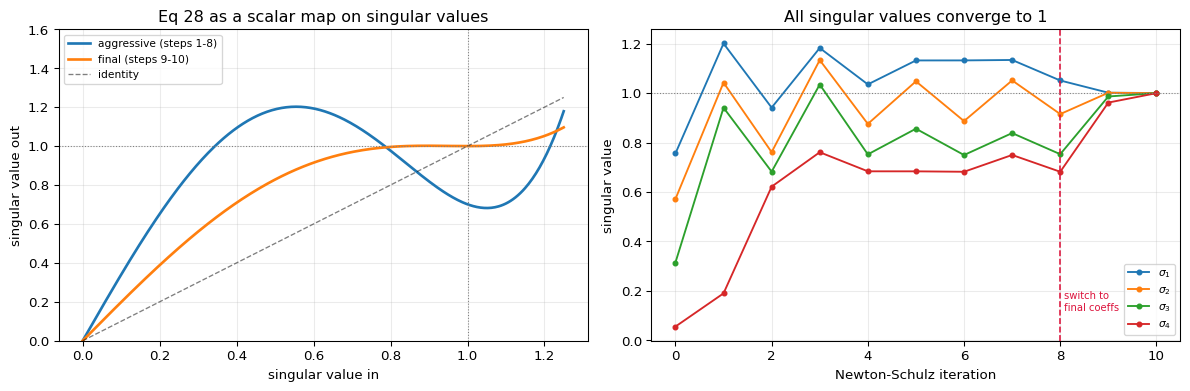

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

ax = axes[0]
s = np.linspace(0, 1.25, 400)
ax.plot(s, poly(s, A_AGG, B_AGG, C_AGG), lw=2, label='aggressive (steps 1-8)')
ax.plot(s, poly(s, A_FIN, B_FIN, C_FIN), lw=2, label='final (steps 9-10)')
ax.plot(s, s, 'k--', lw=1, alpha=.5, label='identity')
ax.axhline(1, color='grey', lw=.8, ls=':')
ax.axvline(1, color='grey', lw=.8, ls=':')
ax.set_xlabel('singular value in'); ax.set_ylabel('singular value out')
ax.set_title('Eq 28 as a scalar map on singular values')
ax.legend(fontsize=8); ax.grid(alpha=.25); ax.set_ylim(0, 1.6)

ax = axes[1]
Hn = np.array(hist)
for j in range(Hn.shape[1]):
    ax.plot(range(len(hist)), Hn[:, j], marker='o', ms=3.5, lw=1.4,
            label=f'$\\sigma_{j+1}$')
ax.axvline(8, color='crimson', ls='--', lw=1.2)
ax.text(8.08, 0.12, 'switch to\nfinal coeffs', fontsize=7.5, color='crimson')
ax.axhline(1, color='grey', lw=.8, ls=':')
ax.set_xlabel('Newton-Schulz iteration'); ax.set_ylabel('singular value')
ax.set_title('All singular values converge to 1')
ax.legend(fontsize=8); ax.grid(alpha=.25)

plt.tight_layout(); plt.show()

## 8. Putting the efficiency claim back together

Section 1 opened with the KV cache of a BF16 GQA-8 baseline at one million
tokens. Now every piece needed to rebuild DeepSeek's side of that comparison is
on the table:

- CSA stores $n/4$ entries, HCA stores $n/128$, interleaved across the layers
- each entry is **one** vector of width $c = 512$, shared by all 64 heads (MQA), not one per head
- there is no separate value cache — the entry is both key and value
- storage is mixed precision: BF16 for the 64 RoPE dimensions, FP8 for the other 448

The last point is easy to skip past and worth a sentence: FP8 halves the cost of
88% of each entry, which is where the "nearly half" saving in the paper comes
from.

In [16]:
banner("REBUILDING THE ~2% KV CACHE CLAIM")

n_ctx, LAY = 1_000_000, 43
c_real, n_rope_dims = 512, 64

step("Baseline: BF16 GQA-8, head dim 128, per layer")
base_tok_layer = 2 * 8 * 128 * 2
base_total = base_tok_layer * n_ctx * LAY
print(f"  keys + values, 8 kv-heads x 128 dims x 2 B = {base_tok_layer:,} B/token/layer")
print(f"  x {n_ctx:,} x {LAY} layers = {base_total/2**30:,.1f} GiB")

step("DeepSeek-V4: bytes per compressed entry")
entry_b = n_rope_dims*2 + (c_real-n_rope_dims)*1     # BF16 RoPE dims, FP8 rest
entry_bf16 = c_real*2
print(f"  {n_rope_dims} RoPE dims in BF16  = {n_rope_dims*2:>4} B")
print(f"  {c_real-n_rope_dims} other dims in FP8   = {(c_real-n_rope_dims):>4} B")
print(f"  total per entry            = {entry_b:>4} B"
      f"   (vs {entry_bf16} B if all BF16 -> {entry_b/entry_bf16*100:.0f}%)")
print(f"  and ONE entry serves all 64 heads, as key and as value.")

step("Per layer, at 1M context")
csa_entries, hca_entries = n_ctx//4, n_ctx//128
csa_bytes = csa_entries * entry_b
hca_bytes = hca_entries * entry_b
print(f"  CSA layer: {csa_entries:>9,} entries x {entry_b} B"
      f" = {csa_bytes/2**30:>8.3f} GiB")
print(f"  HCA layer: {hca_entries:>9,} entries x {entry_b} B"
      f" = {hca_bytes/2**30:>8.3f} GiB")

step("Whole model: 2 sliding-window layers, then CSA/HCA interleaved")
n_swa = 2
n_rest = LAY - n_swa
n_csa, n_hca = n_rest//2, n_rest - n_rest//2
swa_bytes = 128 * entry_b            # n_win = 128 uncompressed entries
total = n_csa*csa_bytes + n_hca*hca_bytes + n_swa*swa_bytes
print(f"  {n_csa} CSA layers + {n_hca} HCA layers + {n_swa} SWA layers")
print(f"    CSA total = {n_csa*csa_bytes/2**30:>8.2f} GiB")
print(f"    HCA total = {n_hca*hca_bytes/2**30:>8.2f} GiB")
print(f"    SWA total = {n_swa*swa_bytes/2**30:>8.5f} GiB  (negligible)")
print(f"    ---------------------------")
print(f"    DeepSeek-V4 = {total/2**30:>6.2f} GiB")
print(f"    baseline    = {base_total/2**30:>6.1f} GiB")
print()
ratio = total/base_total*100
print(f"  ratio = {ratio:.1f}% of the BF16 GQA-8 baseline")
print(f"  The paper states 'approximately 2%'. This reconstruction gives"
      f" {ratio:.1f}%,")
print(f"  which lands on the claim using only the numbers stated in the report.")
print()
print(f"  Caveat worth stating: the per-layer CSA/HCA split is an even")
print(f"  interleave inferred from 'used in an interleaved manner'. The paper")
print(f"  does not give the exact per-layer assignment, so treat {ratio:.1f}% as a")
print(f"  reconstruction of the right magnitude, not a reproduction.")

  REBUILDING THE ~2% KV CACHE CLAIM

Baseline: BF16 GQA-8, head dim 128, per layer
  keys + values, 8 kv-heads x 128 dims x 2 B = 4,096 B/token/layer
  x 1,000,000 x 43 layers = 164.0 GiB

DeepSeek-V4: bytes per compressed entry
  64 RoPE dims in BF16  =  128 B
  448 other dims in FP8   =  448 B
  total per entry            =  576 B   (vs 1024 B if all BF16 -> 56%)
  and ONE entry serves all 64 heads, as key and as value.

Per layer, at 1M context
  CSA layer:   250,000 entries x 576 B =    0.134 GiB
  HCA layer:     7,812 entries x 576 B =    0.004 GiB

Whole model: 2 sliding-window layers, then CSA/HCA interleaved
  20 CSA layers + 21 HCA layers + 2 SWA layers
    CSA total =     2.68 GiB
    HCA total =     0.09 GiB
    SWA total =  0.00014 GiB  (negligible)
    ---------------------------
    DeepSeek-V4 =   2.77 GiB
    baseline    =  164.0 GiB

  ratio = 1.7% of the BF16 GQA-8 baseline
  The paper states 'approximately 2%'. This reconstruction gives 1.7%,
  which lands on the cla

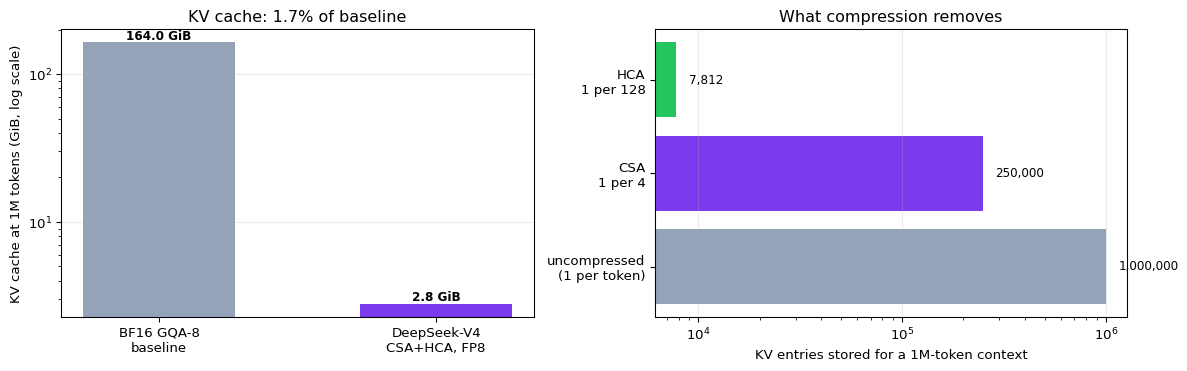

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))

ax = axes[0]
names = ['BF16 GQA-8\nbaseline', 'DeepSeek-V4\nCSA+HCA, FP8']
vals  = [base_total/2**30, total/2**30]
bars = ax.bar(names, vals, color=['#94a3b8', '#7c3aed'], width=.55)
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v*1.05, f'{v:,.1f} GiB',
            ha='center', fontsize=9, fontweight='bold')
ax.set_yscale('log'); ax.set_ylabel('KV cache at 1M tokens (GiB, log scale)')
ax.set_title(f'KV cache: {ratio:.1f}% of baseline')
ax.grid(alpha=.25, axis='y')

ax = axes[1]
labels = ['uncompressed\n(1 per token)', f'CSA\n1 per 4', f'HCA\n1 per 128']
counts = [n_ctx, csa_entries, hca_entries]
bars = ax.barh(labels, counts, color=['#94a3b8', '#7c3aed', '#22c55e'])
for b, v in zip(bars, counts):
    ax.text(v*1.15, b.get_y()+b.get_height()/2, f'{v:,}',
            va='center', fontsize=9)
ax.set_xscale('log'); ax.set_xlabel('KV entries stored for a 1M-token context')
ax.set_title('What compression removes')
ax.grid(alpha=.25, axis='x')

plt.tight_layout(); plt.show()

## 9. What to take away

The three mechanisms are answers to three different pressures, and it is worth
separating them:

**mHC is about depth.** Widening the residual stream helps, but only if the
mixing matrix cannot amplify. Constraining $B_l$ to doubly stochastic makes the
map provably non-expansive and — because the Birkhoff polytope is closed under
multiplication — keeps it non-expansive at any depth. Sinkhorn–Knopp is just the
projection that gets you there, 20 iterations per layer.

**CSA and HCA are about context length.** Both compress KV entries by pooling
with a learned per-channel softmax. CSA compresses gently ($1/4$, overlapped) and
then *selects* with a cheap ReLU-based indexer; HCA compresses hard ($1/128$) and
attends densely because there is so little left. Interleaving them gives a
fine sparse view and a coarse dense view of the same million tokens.

**Muon is about the optimiser.** Orthogonalising the update equalises the
singular values so no direction dominates, and hybrid Newton–Schulz gets there in
10 matrix polynomials instead of an SVD.

The details in section 5 are not decoration. Shared key/value halves the cache
but leaks absolute position, which forces the $\text{RoPE}(-i)$ correction on
outputs. Compression creates a local blind spot, which forces the sliding-window
branch. Softmax forces every head to attend somewhere, which the attention sink
undoes. Each one exists because the mechanism before it broke something.

### Verified in this notebook

- Hyper-connections reduce exactly to $x + F(x)$ at $n_{\text{hc}}=1$
- Sinkhorn–Knopp converges to doubly stochastic, $\|B\|_2 = 1$ exactly, and stays so through 43 layers of products
- CSA compression by hand matches the array computation; overlap gives $1/m$, not $1/2m$
- The lightning indexer's top-$k$ matches a brute-force ranking
- $\text{RoPE}(-i)$ after $\text{RoPE}(j)$ depends only on $j-i$ — to $10^{-17}$
- Newton–Schulz after 10 steps matches $UV^T$ from an exact SVD
- The KV cache reconstruction lands on the paper's ~2% claim

### Source

Everything above follows DeepSeek-AI, *DeepSeek-V4: Towards Highly Efficient
Million-Token Context Intelligence*, [arXiv:2606.19348](https://arxiv.org/abs/2606.19348),
26 April 2026. Equation numbers match the report. Where the report leaves
something unspecified — the exact per-layer CSA/HCA assignment — that is flagged
in the text rather than guessed silently.